# Mini Project: Reproduce and Extend
## *Predicting Airbnb Listing Price Across Different Cities*

**Reference:** Luo, Zhou & Zhou (2019), *Predicting Airbnb Listing Price Across Different Cities*

### Project objectives
1. **Part 1 - Reproduce** the reference paper's regression experiments as closely as the supplied data allow, and compare our results with the reported values (MSE and R²).
2. **Part 2 - Extend** the comparison with one model the paper does not use: **Extra Trees Regression**, trained and evaluated on exactly the same splits, preprocessing and metrics.
3. Explain differences between the reported results and ours.

### Data used
`data/AB_NYC_2019.csv` (NYC), `data/Paris 2019.csv` (Paris) and `data/Berlin 2019.csv` (Berlin).

> **Reproducibility note.** The paper's three files all had 96 raw columns. The supplied NYC and Berlin files are 16-column files (no bedrooms, accommodates, review scores, amenities, ...), while the supplied Paris file has 96 columns. To keep the cities comparable (and the cross-city experiment valid) only information **present in all three files** is used. This is therefore a **closest-version reproduction**, not an exact rerun. The notebook keeps the paper's price cut-off, 70/20/10 split, metrics, model families and (where the data allow) its feature groups.

## 1. Reference-paper methodology

- Cities: **New York City, Paris, Berlin** (2019 Airbnb listings).
- Label: nightly price; listings above **$500** removed for the main comparison; log transformation studied with XGBoost.
- Split: **70% train / 20% validation / 10% test**.
- Feature groups: **continuous** (28 features, imputed and standardised), **categorical** (one-hot), **text** (TF-IDF on unigrams and bigrams, then truncated SVD to 50 dimensions per text field) and **date**. The date features were found to be uninformative and are not in the paper's final feature set (continuous + categorical + text).
- Models: linear regression with L2 regularisation, KNN, Random Forest, XGBoost, and a neural network (MLP, hidden sizes 128/512/64, ReLU, Adam, learning rate 1e-4, weight decay 1e-5, batch size 64).
- Transfer experiments: a smaller MLP (hidden 64/32, SGD with Nesterov momentum, early stopping) trained on NYC, Paris and NYC+Paris, evaluated on their own test sets (Table 6) and on the unseen Berlin data (Table 7), with the log-price label.
- Metrics: **MSE** and **R²**.

### Feature sets used in this notebook

| Name | Contents | Closest paper analogue |
|---|---|---|
| **C** | numeric columns present in all three supplied files | Table 1 (continuous features only) |
| **C+O+T** | **C** + categorical (`room_type`, coarse area) + text (listing `name`, TF-IDF 1-2 grams -> SVD 50) | Tables 4-5 (continuous + categorical + text) |

Both are run, so the notebook can be compared with the paper's Table 1 (feature set C) and Tables 4-5 (feature set C+O+T).

## 2. Reported reference results

Table 1 (NYC, continuous features, price <= $500, test set):

| Model | Reported Test MSE | Reported Test R² |
|---|---:|---:|
| Linear Regression | 3541.99 | 0.497 |
| KNN | 4760.61 | 0.323 |
| Random Forest | 2427.05 | 0.655 |
| Neural Network | 2367.44 | 0.665 |
| XGBoost | 2357.83 | 0.665 |

Other reported values used later: XGBoost with continuous + categorical + text features (NYC test R² 0.706, Paris 0.691 with the $500 cut-off); XGBoost with label transformations (Tables 2, 4, 5); MLP within-city vs combined training (Table 6); and MLP trained on NYC / Paris / NYC+Paris and tested on Berlin (Table 7). They are typed in as reference constants in the cells where they are compared, and are never mixed up with computed results.

The paper does **not** report Extra Trees, so there is no reported value for that model.

In [1]:
# 3. Imports and configuration
from pathlib import Path
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor      # pip install xgboost

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---------------- Experiment configuration (edit here if needed) ----------------
PRICE_CAP = 500                          # the paper's price threshold
TEXT_SVD_DIM = 50                        # paper: 50 SVD components per text field
FEATURE_SETS_TO_RUN = ["C", "C+O+T"]     # see section 1
PRIMARY_FEATURE_SET = "C+O+T"            # used for the NYC validation-set check and the overfitting read-out

assert PRIMARY_FEATURE_SET in FEATURE_SETS_TO_RUN
print("Feature sets:", FEATURE_SETS_TO_RUN, "| primary:", PRIMARY_FEATURE_SET)


Feature sets: ['C', 'C+O+T'] | primary: C+O+T


## 4. Dataset configuration

The three CSV files are read directly from the `data` folder next to the notebook.

In [2]:
DATA_PATHS = {
    "NYC":    Path("data/AB_NYC_2019.csv"),
    "Paris":  Path("data/Paris 2019.csv"),
    "Berlin": Path("data/Berlin 2019.csv"),
}

for city, path in DATA_PATHS.items():
    assert path.is_file(), f"{city} file not found: {path.resolve()}"
print("Datasets:", {c: p.name for c, p in DATA_PATHS.items()})


Datasets: {'NYC': 'AB_NYC_2019.csv', 'Paris': 'Paris 2019.csv', 'Berlin': 'Berlin 2019.csv'}


## 5. Loading and cleaning the 2019 Airbnb data

For every city we:
1. Parse the `price` column (handles `$125.00`-style strings) and keep `0 < price <= $500`.
2. Keep numeric, non-empty, non-constant columns, excluding identifiers and price/revenue/occupancy-like fields, and take the **intersection across the three cities** -> feature set **C**.
3. Build the shared categorical and text inputs for feature set **C+O+T**:
   - `room_type` (present in all three files);
   - `area`, a coarse location label: `neighbourhood_group` (NYC boroughs, Berlin districts) or, when that column is empty, `neighbourhood_cleansed` (Paris arrondissements);
   - `name_text`, the listing title (the only text field present in all three files).
4. Missing categorical values become `"unknown"`, missing text becomes an empty string. Numeric imputation is done later inside the pipeline using **training data only**.

In [3]:
PAPER_RAW_ROWS = {"NYC": 44317, "Paris": 59881, "Berlin": 22552}   # listing counts reported in the paper
AREA_SOURCES = ["neighbourhood_group", "neighbourhood_group_cleansed", "neighbourhood_cleansed"]
ROOM_COL = "room_type"
TEXT_COL = "name_text"
EXCLUDED_NUMERIC = {"price", "price_numeric", "id", "host_id", "scrape_id", "license", "host_profile_id"}

def parse_price(series):
    # Handles values such as "$123.00", "123", "1,234.50", etc.
    return pd.to_numeric(
        series.astype(str).str.replace(r"[^0-9.\-]", "", regex=True),
        errors="coerce"
    )

def pick_area_column(df):
    for col in AREA_SOURCES:
        if col in df.columns and df[col].notna().mean() >= 0.5:
            return col
    return None

def load_city(path, price_cap=PRICE_CAP):
    df = pd.read_csv(path, low_memory=False)
    n_file_rows = len(df)
    if "price" not in df.columns:
        raise ValueError(f"'price' column not found in {path}")

    df["price_numeric"] = parse_price(df["price"])
    keep = df["price_numeric"].notna() & (df["price_numeric"] > 0)
    if price_cap is not None:
        keep &= df["price_numeric"] <= price_cap
    df = df.loc[keep].copy()

    # Numeric candidates (before adding the engineered text/categorical columns).
    candidates = []
    for c in df.select_dtypes(include=np.number).columns:
        lc = c.lower()
        if c in EXCLUDED_NUMERIC:
            continue
        if any(token in lc for token in ["price_quote", "revenue", "occupancy"]):
            continue
        if df[c].notna().sum() == 0 or df[c].nunique(dropna=True) <= 1:
            continue
        candidates.append(c)

    area_col = pick_area_column(df)
    if area_col is not None:
        df["area"] = df[area_col].fillna("unknown").astype(str).str.strip()
    else:
        df["area"] = "unknown"
    if ROOM_COL in df.columns:
        df[ROOM_COL] = df[ROOM_COL].fillna("unknown").astype(str).str.strip()
    else:
        df[ROOM_COL] = "unknown"
    if "name" in df.columns:
        df[TEXT_COL] = df["name"].fillna("").astype(str)
    else:
        df[TEXT_COL] = ""

    return df, candidates, {"rows_in_file": n_file_rows, "area_source": area_col}

raw_data, feature_candidates, load_info = {}, {}, {}
for city, path in DATA_PATHS.items():
    df, candidates, info = load_city(path)
    raw_data[city] = df
    feature_candidates[city] = candidates
    load_info[city] = info
    print(
        f"{city:6s} | rows in file: {info['rows_in_file']:,} (paper: {PAPER_RAW_ROWS[city]:,}) | "
        f"rows after price filter: {len(df):,} | numeric candidates: {len(candidates)} | "
        f"area column: {info['area_source']}"
    )

common_features = sorted(set.intersection(*[set(v) for v in feature_candidates.values()]))
CAT_COLS = [c for c in [ROOM_COL, "area"] if all(raw_data[city][c].nunique() > 1 for city in raw_data)]
MODEL_COLUMNS = common_features + CAT_COLS + [TEXT_COL]

print(f"\nFeature set C (numeric, common to all three cities): {len(common_features)}")
print(common_features)
print("Categorical columns for C+O+T:", CAT_COLS)
print("Text column for C+O+T:", TEXT_COL, "-> TF-IDF (1-2 grams) -> SVD", TEXT_SVD_DIM)
for city, df in raw_data.items():
    print(f"  {city}: room types = {df[ROOM_COL].nunique()}, areas = {df['area'].nunique()}")

NYC    | rows in file: 48,895 (paper: 44,317) | rows after price filter: 47,840 | numeric candidates: 7 | area column: neighbourhood_group
Paris  | rows in file: 59,881 (paper: 59,881) | rows after price filter: 59,021 | numeric candidates: 26 | area column: neighbourhood_cleansed
Berlin | rows in file: 22,552 (paper: 22,552) | rows after price filter: 22,470 | numeric candidates: 7 | area column: neighbourhood_group

Feature set C (numeric, common to all three cities): 7
['availability_365', 'calculated_host_listings_count', 'latitude', 'longitude', 'minimum_nights', 'number_of_reviews', 'reviews_per_month']
Categorical columns for C+O+T: ['room_type', 'area']
Text column for C+O+T: name_text -> TF-IDF (1-2 grams) -> SVD 50
  NYC: room types = 3, areas = 5
  Paris: room types = 3, areas = 20
  Berlin: room types = 3, areas = 12


In [4]:
# Dataset summary for the report
summary_rows = []
for city, df in raw_data.items():
    summary_rows.append({
        "City": city,
        "Rows in file": load_info[city]["rows_in_file"],
        "Rows in paper": PAPER_RAW_ROWS[city],
        "Rows after price filter": len(df),
        "Numeric features (C)": len(common_features),
        "Room types": df[ROOM_COL].nunique(),
        "Areas": df["area"].nunique(),
        "Area source column": load_info[city]["area_source"],
        "Minimum price": df["price_numeric"].min(),
        "Median price": df["price_numeric"].median(),
        "Maximum price": df["price_numeric"].max(),
    })

dataset_summary = pd.DataFrame(summary_rows)
display(dataset_summary)

,City,Rows in file,Rows in paper,Rows after price filter,Numeric features (C),Room types,Areas,Area source column,Minimum price,Median price,Maximum price
0,NYC,48895,44317,47840,7,3,5,neighbourhood_group,10.0,101.0,500.0
1,Paris,59881,59881,59021,7,3,20,neighbourhood_cleansed,8.0,79.0,500.0
2,Berlin,22552,22552,22470,7,3,12,neighbourhood_group,1.0,45.0,500.0


## 6. Train / validation / test split

The paper describes a **70% / 20% / 10%** split. We reserve 30% and then split it 2:1 into validation (20%) and test (10%). The same function and seed are used for every city and model, so all models are compared on identical data.

In [5]:
def make_split(df):
    X = df[MODEL_COLUMNS].copy()
    y = df["price_numeric"].copy()

    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, random_state=RANDOM_STATE
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=1/3, random_state=RANDOM_STATE
    )
    return X_train, X_val, X_test, y_train, y_val, y_test

splits = {}
for city, df in raw_data.items():
    splits[city] = make_split(df)
    X_train, X_val, X_test, y_train, y_val, y_test = splits[city]
    print(
        f"{city:6s} -> train={len(X_train):,}, "
        f"validation={len(X_val):,}, test={len(X_test):,}"
    )

NYC    -> train=33,488, validation=9,568, test=4,784
Paris  -> train=41,314, validation=11,804, test=5,903
Berlin -> train=15,729, validation=4,494, test=2,247


## 7. Preprocessing pipeline

Everything is fitted **on the training data only** (no leakage):

- **C:** median imputation, then standardisation of the numeric columns.
- **C+O+T:** the same numeric block, plus
  - one-hot encoding of `room_type` and `area` (unseen categories are ignored);
  - TF-IDF on the listing `name` (unigrams and bigrams, `min_df=5`), reduced with truncated SVD to 50 dimensions and standardised, as in the paper.

The paper also tested a date block and found it uninformative, so it is left out here too.

In [6]:
def make_numeric_block():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

def make_text_block():
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=20000)),
        ("svd", TruncatedSVD(n_components=TEXT_SVD_DIM, random_state=RANDOM_STATE)),
        ("scaler", StandardScaler()),
    ])

def make_preprocessor(feature_set=PRIMARY_FEATURE_SET):
    """Column preprocessing for feature set 'C' or 'C+O+T'. Input X must contain MODEL_COLUMNS."""
    if feature_set not in ("C", "C+O+T"):
        raise ValueError(f"Unknown feature set: {feature_set}")
    blocks = [("num", make_numeric_block(), common_features)]
    if feature_set == "C+O+T":
        if CAT_COLS:
            blocks.append(("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS))
        blocks.append(("txt", make_text_block(), TEXT_COL))
    return ColumnTransformer(blocks, remainder="drop", sparse_threshold=0.0)

### Hyperparameter note

The paper gives the MLP architecture and optimizer settings explicitly, but says the other sklearn models use default settings and does not list a full XGBoost configuration. The notebook therefore uses:
- the paper's reported MLP settings (hidden sizes 128/512/64, Adam, learning rate 1e-4, weight decay 1e-5, batch size 64);
- standard sklearn settings for Ridge, KNN and Random Forest;
- a fixed, documented XGBoost configuration.

This is one reason the numbers should not be expected to match the paper exactly.


In [7]:
def build_models():
    return {
        "Ridge regression": Ridge(alpha=1.0),
        "K-nearest neighbors": KNeighborsRegressor(),
        "Random forest": RandomForestRegressor(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ),
        "Neural network": MLPRegressor(
            hidden_layer_sizes=(128, 512, 64),
            activation="relu",
            solver="adam",
            learning_rate_init=1e-4,
            alpha=1e-5,
            batch_size=64,
            max_iter=220,
            early_stopping=True,
            validation_fraction=0.10,
            tol=1e-4,
            n_iter_no_change=10,
            random_state=RANDOM_STATE
        ),
        "XGBoost": XGBRegressor(
            n_estimators=250,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.90,
            colsample_bytree=0.90,
            objective="reg:squarederror",
            random_state=RANDOM_STATE,
            n_jobs=2
        ),
    }

def make_xgb():
    return build_models()["XGBoost"]

def evaluate_model(model, split):
    """Fit a pipeline on a (X_train, X_val, X_test, y_train, y_val, y_test) split and
    return train/validation/test MSE and R² (price scale) plus the fit time."""
    X_train, X_val, X_test, y_train, y_val, y_test = split
    t0 = time.time()
    model.fit(X_train, y_train)
    metrics = {}
    for part, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
        pred = model.predict(X)
        metrics[f"{part}_mse"] = mean_squared_error(y, pred)
        metrics[f"{part}_r2"] = r2_score(y, pred)
    metrics["seconds"] = time.time() - t0
    return metrics


## 8. Part 1 - Train the reference models

Five model families from the paper (Ridge as the L2 linear baseline, KNN, Random Forest, MLP, XGBoost) are trained on every city for every feature set, on the raw price label with the $500 cut-off, and evaluated on the held-out test set.

In [8]:
all_results = []

for fs in FEATURE_SETS_TO_RUN:
    for city, split in splits.items():
        print(f"\n===== {city} | feature set {fs} =====")
        for name, estimator in build_models().items():
            pipeline = Pipeline([("preprocess", make_preprocessor(fs)), ("model", estimator)])
            m = evaluate_model(pipeline, split)
            all_results.append({"feature_set": fs, "city": city, "model": name, "label": "raw", **m})
            print(f"{name:22s} | Test MSE = {m['test_mse']:.2f} | "
                  f"Test R² = {m['test_r2']:.4f} | {m['seconds']:.0f}s")

results_df = pd.DataFrame(all_results)
display(results_df.round(4))



===== NYC | feature set C =====
Ridge regression       | Test MSE = 7075.95 | Test R² = 0.1110 | 0s
K-nearest neighbors    | Test MSE = 6543.30 | Test R² = 0.1779 | 1s
Random forest          | Test MSE = 5330.27 | Test R² = 0.3303 | 3s
Neural network         | Test MSE = 5547.86 | Test R² = 0.3029 | 218s
XGBoost                | Test MSE = 5196.62 | Test R² = 0.3471 | 1s

===== Paris | feature set C =====
Ridge regression       | Test MSE = 4136.35 | Test R² = 0.1557 | 0s
K-nearest neighbors    | Test MSE = 4118.79 | Test R² = 0.1593 | 4s
Random forest          | Test MSE = 3543.18 | Test R² = 0.2768 | 3s
Neural network         | Test MSE = 3582.87 | Test R² = 0.2687 | 147s
XGBoost                | Test MSE = 3351.23 | Test R² = 0.3160 | 1s

===== Berlin | feature set C =====
Ridge regression       | Test MSE = 1890.11 | Test R² = 0.0361 | 0s
K-nearest neighbors    | Test MSE = 1783.36 | Test R² = 0.0905 | 1s
Random forest          | Test MSE = 1645.09 | Test R² = 0.1610 | 1s
Neural n

,feature_set,city,model,label,train_mse,train_r2,val_mse,val_r2,test_mse,test_r2,seconds
0,C,NYC,Ridge regression,raw,6765.2060,0.1216,6805.8795,0.1304,7075.9497,0.1110,0.0708
1,C,NYC,K-nearest neighbors,raw,4069.9364,0.4716,6165.4739,0.2122,6543.3027,0.1779,1.2041
2,C,NYC,Random forest,raw,712.3339,0.9075,5162.9320,0.3403,5330.2683,0.3303,2.6979
3,C,NYC,Neural network,raw,5283.8932,0.3139,5454.9786,0.3030,5547.8586,0.3029,218.3647
4,C,NYC,XGBoost,raw,4259.1245,0.4470,5056.3892,0.3539,5196.6182,0.3471,0.8982
5,C,Paris,Ridge regression,raw,4120.3205,0.1404,3905.1459,0.1387,4136.3515,0.1557,0.0409
6,C,Paris,K-nearest neighbors,raw,2653.6714,0.4464,3796.6542,0.1626,4118.7948,0.1593,3.6877
7,C,Paris,Random forest,raw,476.1215,0.9007,3297.9378,0.2726,3543.1785,0.2768,3.4768
8,C,Paris,Neural network,raw,3498.4288,0.2701,3382.2228,0.2540,3582.8745,0.2687,147.0717
9,C,Paris,XGBoost,raw,2774.2854,0.4212,3154.0622,0.3043,3351.2343,0.3160,0.8738


## Validation-set check

The main comparison uses the test set, but we also evaluate **XGBoost on the NYC validation set** for the primary feature set, as a sanity check that the validation partition is separate from the test set and gives similar numbers.

In [9]:
# Validation-set check for NYC XGBoost (primary feature set).
city = "NYC"
X_train, X_val, X_test, y_train, y_val, y_test = splits[city]
validation_xgb = Pipeline([
    ("preprocess", make_preprocessor(PRIMARY_FEATURE_SET)),
    ("model", make_xgb())
])
validation_xgb.fit(X_train, y_train)
val_pred = validation_xgb.predict(X_val)
test_pred = validation_xgb.predict(X_test)
print(f"NYC XGBoost ({PRIMARY_FEATURE_SET}) validation MSE: {mean_squared_error(y_val, val_pred):.2f} | R²: {r2_score(y_val, val_pred):.4f}")
print(f"NYC XGBoost ({PRIMARY_FEATURE_SET}) test       MSE: {mean_squared_error(y_test, test_pred):.2f} | R²: {r2_score(y_test, test_pred):.4f}")

NYC XGBoost (C+O+T) validation MSE: 3288.14 | R²: 0.5798
NYC XGBoost (C+O+T) test       MSE: 3400.51 | R²: 0.5727


## 9. Part 1 - Reproduction comparison with the reference paper

**Table 1 comparison.** The paper's Table 1 uses continuous features only, so it is compared with our feature set **C**. The paper's own continuous set has 28 features, ours has the columns shared by the three supplied files, so the purpose is to see whether the same model families produce the same *pattern*, not to claim exact numerical agreement.

In [10]:
# Paper Table 1: NYC continuous-feature experiment (thresholded price, train and test metrics).
# The paper calls the linear baseline "Linear regression"; this notebook uses Ridge (L2).
reference_table1 = pd.DataFrame({
    "model": ["Ridge regression", "K-nearest neighbors", "Random forest",
              "Neural network", "XGBoost"],
    "paper_model": ["Linear regression (L2)", "K-nearest neighbor",
                    "Random forest", "Neural network", "XGBoost"],
    "reference_train_mse": [3514.64, 4466.30, 1706.86, 2059.43, 2273.98],
    "reference_train_r2": [0.489, 0.351, 0.752, 0.702, 0.669],
    "reference_test_mse": [3541.99, 4760.61, 2427.05, 2367.44, 2357.83],
    "reference_test_r2": [0.497, 0.323, 0.655, 0.665, 0.665]
})

def build_table1_comparison(feature_set):
    nyc = results_df[(results_df["city"] == "NYC") & (results_df["feature_set"] == feature_set)]
    merged = nyc.merge(reference_table1, on="model", how="inner")
    out = merged[[
        "model", "paper_model",
        "reference_train_mse", "train_mse",
        "reference_train_r2", "train_r2",
        "reference_test_mse", "test_mse",
        "reference_test_r2", "test_r2"
    ]].copy()
    out.columns = [
        "Notebook model", "Paper model",
        "Reported train MSE", "Our train MSE",
        "Reported train R²", "Our train R²",
        "Reported test MSE", "Our test MSE",
        "Reported test R²", "Our test R²"
    ]
    return out

comparison = None
if "C" in FEATURE_SETS_TO_RUN:
    comparison = build_table1_comparison("C")
    print("Reported (paper Table 1) vs ours, NYC, feature set C (numeric only):")
    display(comparison.round(4))
else:
    print("Feature set 'C' was not run, so the Table 1 comparison is skipped.")

if "C+O+T" in FEATURE_SETS_TO_RUN:
    print("\nSame models on feature set C+O+T (closer to the paper's final feature set), vs the paper's Table 1 values:")
    display(build_table1_comparison("C+O+T").round(4))

Reported (paper Table 1) vs ours, NYC, feature set C (numeric only):


,Notebook model,Paper model,Reported train MSE,Our train MSE,Reported train R²,Our train R²,Reported test MSE,Our test MSE,Reported test R²,Our test R²
0,Ridge regression,Linear regression (L2),3514.64,6765.2060,0.489,0.1216,3541.99,7075.9497,0.497,0.1110
1,K-nearest neighbors,K-nearest neighbor,4466.30,4069.9364,0.351,0.4716,4760.61,6543.3027,0.323,0.1779
2,Random forest,Random forest,1706.86,712.3339,0.752,0.9075,2427.05,5330.2683,0.655,0.3303
3,Neural network,Neural network,2059.43,5283.8932,0.702,0.3139,2367.44,5547.8586,0.665,0.3029
4,XGBoost,XGBoost,2273.98,4259.1245,0.669,0.4470,2357.83,5196.6182,0.665,0.3471



Same models on feature set C+O+T (closer to the paper's final feature set), vs the paper's Table 1 values:


,Notebook model,Paper model,Reported train MSE,Our train MSE,Reported train R²,Our train R²,Reported test MSE,Our test MSE,Reported test R²,Our test R²
0,Ridge regression,Linear regression (L2),3514.64,4145.3727,0.489,0.4618,3541.99,4264.1514,0.497,0.4642
1,K-nearest neighbors,K-nearest neighbor,4466.30,3604.9797,0.351,0.5319,4760.61,5502.1190,0.323,0.3087
2,Random forest,Random forest,1706.86,489.1719,0.752,0.9365,2427.05,3655.3345,0.655,0.5407
3,Neural network,Neural network,2059.43,3354.7092,0.702,0.5644,2367.44,3733.1388,0.665,0.5310
4,XGBoost,XGBoost,2273.98,2296.0833,0.669,0.7019,2357.83,3400.5103,0.665,0.5727


In [11]:
# Paper Tables 4-5: XGBoost with continuous + categorical + text features, price <= $500 (raw label).
reference_xgb_full = pd.DataFrame([
    {"city": "NYC",   "reported_train_mse": 1885.25, "reported_train_r2": 0.724,
     "reported_test_mse": 2078.78, "reported_test_r2": 0.706},
    {"city": "Paris", "reported_train_mse": 1308.47, "reported_train_r2": 0.697,
     "reported_test_mse": 1413.89, "reported_test_r2": 0.691},
])

if "C+O+T" in FEATURE_SETS_TO_RUN:
    ours = results_df[(results_df["model"] == "XGBoost") & (results_df["feature_set"] == "C+O+T")]
    xgb_full_comparison = reference_xgb_full.merge(
        ours[["city", "train_mse", "train_r2", "test_mse", "test_r2"]], on="city", how="left"
    )
    xgb_full_comparison["R² gap (ours - reported, test)"] = (
        xgb_full_comparison["test_r2"] - xgb_full_comparison["reported_test_r2"]
    )
    print("XGBoost, continuous + categorical + text features: reported (paper Tables 4-5) vs ours")
    display(xgb_full_comparison.round(4))
else:
    xgb_full_comparison = None

XGBoost, continuous + categorical + text features: reported (paper Tables 4-5) vs ours


,city,reported_train_mse,reported_train_r2,reported_test_mse,reported_test_r2,train_mse,train_r2,test_mse,test_r2,"R² gap (ours - reported, test)"
0,NYC,1885.25,0.724,2078.78,0.706,2296.0833,0.7019,3400.5103,0.5727,-0.1333
1,Paris,1308.47,0.697,1413.89,0.691,1970.1100,0.5890,2796.3223,0.4292,-0.2618


**Reproduction vs paper.** Test R² of our reproduction next to the paper's reported values: Table 1 (all five models, continuous features, NYC) on the left and XGBoost with continuous + categorical + text features (Tables 4-5, NYC and Paris) on the right.

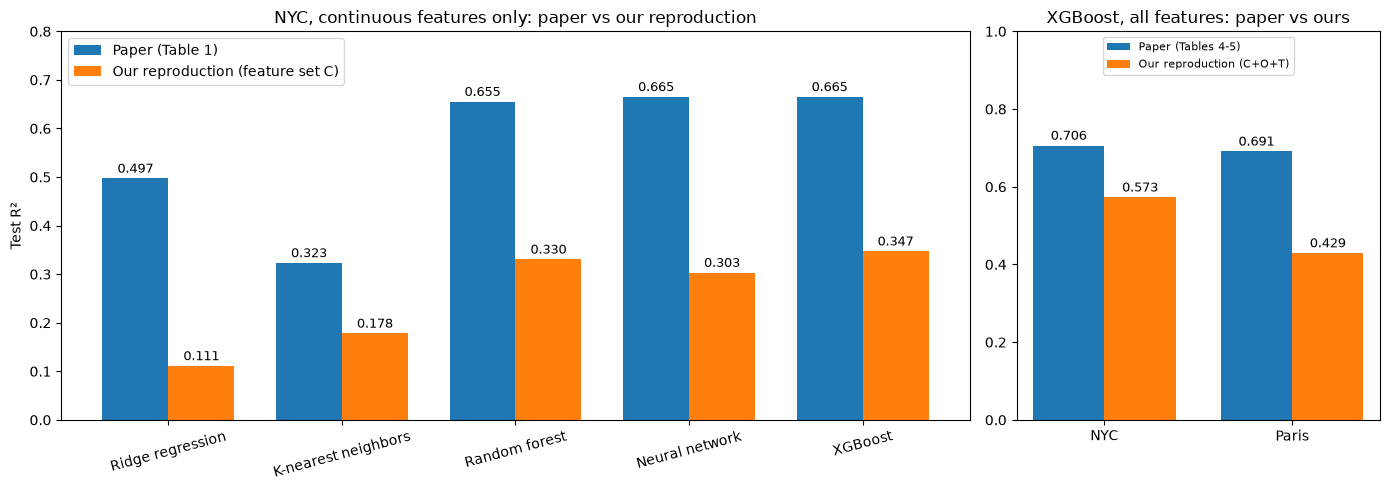

In [12]:
# Part 1: reproduction vs paper, test R² (values come from the comparison tables above)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [5, 2]})

# (a) Paper Table 1: NYC, continuous features -> our feature set C, all five models
ax = axes[0]
x = np.arange(len(comparison))
w = 0.38
bars_paper = ax.bar(x - w / 2, comparison["Reported test R²"], w, label="Paper (Table 1)")
bars_ours = ax.bar(x + w / 2, comparison["Our test R²"], w, label="Our reproduction (feature set C)")
ax.bar_label(bars_paper, fmt="%.3f", padding=2, fontsize=9)
ax.bar_label(bars_ours, fmt="%.3f", padding=2, fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(comparison["Notebook model"], rotation=15)
ax.set_ylabel("Test R²")
ax.set_ylim(0, 0.8)
ax.set_title("NYC, continuous features only: paper vs our reproduction")
ax.legend(loc="upper left")

# (b) Paper Tables 4-5: XGBoost with continuous + categorical + text features -> our C+O+T
ax = axes[1]
x2 = np.arange(len(xgb_full_comparison))
bars_paper = ax.bar(x2 - w / 2, xgb_full_comparison["reported_test_r2"], w, label="Paper (Tables 4-5)")
bars_ours = ax.bar(x2 + w / 2, xgb_full_comparison["test_r2"], w, label="Our reproduction (C+O+T)")
ax.bar_label(bars_paper, fmt="%.3f", padding=2, fontsize=9)
ax.bar_label(bars_ours, fmt="%.3f", padding=2, fontsize=9)
ax.set_xticks(x2)
ax.set_xticklabels(xgb_full_comparison["city"])
ax.set_ylim(0, 1.0)
ax.set_title("XGBoost, all features: paper vs ours")
ax.legend(loc="upper center", fontsize=8)

plt.tight_layout()
plt.show()


In [13]:
# Findings generated from THIS run: every number printed below is read from results_df.
def get_metric(df, city, model, fs, col):
    row = df[(df["city"] == city) & (df["model"] == model) & (df["feature_set"] == fs)]
    return float(row[col].iloc[0])

strong_models = ["Random forest", "Neural network", "XGBoost"]
weak_models = ["Ridge regression", "K-nearest neighbors"]

print("Findings generated from this run (read from results_df, not typed in)")
for fs in FEATURE_SETS_TO_RUN:
    print(f"\n--- Feature set {fs} ---")
    for city in splits:
        sub = results_df[(results_df["feature_set"] == fs) & (results_df["city"] == city)]
        sub = sub.sort_values("test_r2", ascending=False)
        print(f"{city}: " + " > ".join(f"{m} ({v:.3f})" for m, v in zip(sub["model"], sub["test_r2"])))
        s_min = min(get_metric(results_df, city, m, fs, "test_r2") for m in strong_models)
        w_max = max(get_metric(results_df, city, m, fs, "test_r2") for m in weak_models)
        ridge_r2 = get_metric(results_df, city, "Ridge regression", fs, "test_r2")
        knn_r2 = get_metric(results_df, city, "K-nearest neighbors", fs, "test_r2")
        print(f"    RF, MLP and XGBoost all beat Ridge and KNN: {s_min > w_max}")
        print(f"    Ridge vs KNN: Ridge {'>' if ridge_r2 > knn_r2 else '<'} KNN "
              f"(paper, NYC: Ridge 0.497 > KNN 0.323)")

print("\nTrain/test R² gap on NYC vs the paper (a large gap means overfitting):")
gap_rows = []
for _, r in reference_table1.iterrows():
    for fs in FEATURE_SETS_TO_RUN:
        tr = get_metric(results_df, "NYC", r["model"], fs, "train_r2")
        te = get_metric(results_df, "NYC", r["model"], fs, "test_r2")
        gap_rows.append({
            "model": r["model"], "feature set": fs,
            "paper train R²": r["reference_train_r2"], "paper test R²": r["reference_test_r2"],
            "paper gap": r["reference_train_r2"] - r["reference_test_r2"],
            "our train R²": tr, "our test R²": te, "our gap": tr - te,
        })
gap_df = pd.DataFrame(gap_rows)
display(gap_df.round(3))

Findings generated from this run (read from results_df, not typed in)

--- Feature set C ---
NYC: XGBoost (0.347) > Random forest (0.330) > Neural network (0.303) > K-nearest neighbors (0.178) > Ridge regression (0.111)
    RF, MLP and XGBoost all beat Ridge and KNN: True
    Ridge vs KNN: Ridge < KNN (paper, NYC: Ridge 0.497 > KNN 0.323)
Paris: XGBoost (0.316) > Random forest (0.277) > Neural network (0.269) > K-nearest neighbors (0.159) > Ridge regression (0.156)
    RF, MLP and XGBoost all beat Ridge and KNN: True
    Ridge vs KNN: Ridge < KNN (paper, NYC: Ridge 0.497 > KNN 0.323)
Berlin: XGBoost (0.167) > Random forest (0.161) > Neural network (0.144) > K-nearest neighbors (0.091) > Ridge regression (0.036)
    RF, MLP and XGBoost all beat Ridge and KNN: True
    Ridge vs KNN: Ridge < KNN (paper, NYC: Ridge 0.497 > KNN 0.323)

--- Feature set C+O+T ---
NYC: XGBoost (0.573) > Random forest (0.541) > Neural network (0.531) > Ridge regression (0.464) > K-nearest neighbors (0.309)
    

,model,feature set,paper train R²,paper test R²,paper gap,our train R²,our test R²,our gap
0,Ridge regression,C,0.489,0.497,-0.008,0.122,0.111,0.011
1,Ridge regression,C+O+T,0.489,0.497,-0.008,0.462,0.464,-0.002
2,K-nearest neighbors,C,0.351,0.323,0.028,0.472,0.178,0.294
3,K-nearest neighbors,C+O+T,0.351,0.323,0.028,0.532,0.309,0.223
4,Random forest,C,0.752,0.655,0.097,0.908,0.330,0.577
5,Random forest,C+O+T,0.752,0.655,0.097,0.936,0.541,0.396
6,Neural network,C,0.702,0.665,0.037,0.314,0.303,0.011
7,Neural network,C+O+T,0.702,0.665,0.037,0.564,0.531,0.033
8,XGBoost,C,0.669,0.665,0.004,0.447,0.347,0.100
9,XGBoost,C+O+T,0.669,0.665,0.004,0.702,0.573,0.129


### Part 1 results and discussion

**Ranking.** XGBoost has the highest test R² in every city and for both feature sets. Random Forest, the MLP and XGBoost beat Ridge and KNN in all six city/feature-set combinations, as in the paper. In the paper the MLP matches XGBoost (0.665 each); here it is slightly behind Random Forest in five of the six cases (Paris with C+O+T, 0.378 vs 0.376, is the exception).

**Effect of the feature groups.** Adding room type, area and listing-title text (C to C+O+T) raises XGBoost test R² from 0.347 to 0.573 in NYC, from 0.316 to 0.429 in Paris and from 0.167 to 0.377 in Berlin. Ridge in NYC rises from 0.111 to 0.464 (paper: 0.497). On C, KNN beats Ridge in all three cities (NYC 0.178 vs 0.111), the opposite of the paper's order (0.323 vs 0.497). On C+O+T, Ridge beats KNN in all three cities (NYC 0.464 vs 0.309), as in the paper. A plausible explanation is that price is not a linear function of latitude and longitude, which dominate feature set C, whereas room type gives a nearly linear price signal; this was not tested separately.

**Gap to the paper.** NYC XGBoost reaches 0.347 on C (paper 0.665) and 0.573 on C+O+T (paper 0.706, gap 0.133). Paris XGBoost reaches 0.429 (paper 0.691, gap 0.262). The NYC XGBoost validation R² (0.580) is close to its test R² (0.573), so the held-out test split behaves like the validation split.

**Overfitting.** On NYC with feature set C, the train/test R² gaps are far larger than in the paper's Table 1: Random Forest 0.908 vs 0.330 (gap 0.577, paper 0.097), KNN 0.472 vs 0.178 (gap 0.294, paper 0.028) and XGBoost 0.447 vs 0.347 (gap 0.100, paper 0.004). With C+O+T the gaps are 0.396 for Random Forest and 0.129 for XGBoost (paper, XGBoost C+O+T: 0.018). The MLP gap is small (0.564 vs 0.531 with C+O+T) and Ridge shows almost none.

**Why the numbers differ from the paper** (listed in rough order of expected importance; none was isolated by a separate experiment):

- **Feature availability.** The paper's 28 continuous features include listing-size and review-score variables. The supplied NYC and Berlin files are 16-column files without them, so feature set C has only seven numeric columns shared by all three files.
- **Reduced categorical and text information.** The paper used about 20 categorical and 12 text fields. Only `room_type`, a coarse area and the listing `name` exist in all three files, so C+O+T is a reduced version of the paper's feature set.
- **Different NYC file.** The Paris and Berlin files contain exactly the paper's listing counts (59,881 and 22,552 rows), so they appear to be the same listings. The NYC file has 48,895 rows against the paper's 44,317, so it is a different release. After the price filter (0 < price <= $500) the counts are 47,840 / 59,021 / 22,470.
- **Unspecified hyperparameters.** The paper gives full settings only for the MLP; all other settings here are documented choices.
- **Single split.** Differences of about 0.01 R² between models are within what a different random split could change.
- **Library versions** can change results slightly; this is expected to be a minor factor.

MSE is in squared dollars and depends on each file's price distribution, so R² is the more reliable figure for comparison with the paper.

# Part 2 - Additional Model

## Extra Trees Regression

The reference paper evaluates linear regression, KNN, Random Forest, XGBoost and a neural network. It does **not** report `ExtraTreesRegressor`.

**Why this model.** Extra Trees is a close relative of Random Forest, so it is not a radical departure; it is chosen to test a specific question: *does randomising the split thresholds (instead of searching for the best one at each split) reduce the overfitting that fully grown Random Forest trees tend to show, and does it generalise better?* Extra Trees draws split thresholds at random, which in theory lowers variance, and it also trains faster. This allows a direct comparison with Random Forest (same family, different randomisation) and with XGBoost (a different ensembling strategy) on the same splits, preprocessing and metrics.

The extension is evaluated on the same held-out test sets for every city and both feature sets. The results are summarised in the discussion after the comparison tables.

In [14]:
extension_results = []

for fs in FEATURE_SETS_TO_RUN:
    for city, split in splits.items():
        extension_model = Pipeline([
            ("preprocess", make_preprocessor(fs)),
            ("model", ExtraTreesRegressor(
                n_estimators=300,
                max_features=1.0,
                min_samples_leaf=1,
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ])
        m = evaluate_model(extension_model, split)
        extension_results.append({"feature_set": fs, "city": city,
                                  "model": "Extra Trees (extension)", "label": "raw", **m})
        print(f"{city} | {fs}: Extra Trees test MSE={m['test_mse']:.2f}, "
              f"test R²={m['test_r2']:.4f} ({m['seconds']:.0f}s)")

extension_df = pd.DataFrame(extension_results)
display(extension_df.round(4))


NYC | C: Extra Trees test MSE=5336.94, test R²=0.3294 (3s)
Paris | C: Extra Trees test MSE=3503.94, test R²=0.2848 (3s)
Berlin | C: Extra Trees test MSE=1664.60, test R²=0.1511 (1s)
NYC | C+O+T: Extra Trees test MSE=3577.62, test R²=0.5505 (14s)
Paris | C+O+T: Extra Trees test MSE=2946.59, test R²=0.3986 (23s)
Berlin | C+O+T: Extra Trees test MSE=1310.01, test R²=0.3319 (7s)


,feature_set,city,model,label,train_mse,train_r2,val_mse,val_r2,test_mse,test_r2,seconds
0,C,NYC,Extra Trees (extension),raw,0.0004,1.0,5207.9149,0.3345,5336.9367,0.3294,2.6350
1,C,Paris,Extra Trees (extension),raw,0.0096,1.0,3274.2887,0.2778,3503.9410,0.2848,3.3217
2,C,Berlin,Extra Trees (extension),raw,0.0000,1.0,1711.6692,0.1692,1664.6050,0.1511,1.2038
3,C+O+T,NYC,Extra Trees (extension),raw,0.0003,1.0,3457.3672,0.5582,3577.6157,0.5505,14.0585
4,C+O+T,Paris,Extra Trees (extension),raw,0.0000,1.0,2812.5703,0.3796,2946.5921,0.3986,23.4220
5,C+O+T,Berlin,Extra Trees (extension),raw,0.0000,1.0,1306.5902,0.3658,1310.0059,0.3319,6.8969


In [15]:
# Compare all reference-family models and the new extension on the same splits.
comparison_all = pd.concat([
    results_df.assign(type="Reference-family model"),
    extension_df.assign(type="Additional model"),
], ignore_index=True)[["feature_set", "city", "model", "type", "test_mse", "test_r2", "train_r2"]]

display(
    comparison_all
    .sort_values(["feature_set", "city", "test_r2"], ascending=[True, True, False])
    .round(4)
)

best_by_city = (
    comparison_all.loc[comparison_all.groupby(["feature_set", "city"])["test_r2"].idxmax()]
    .sort_values(["feature_set", "city"])
    .reset_index(drop=True)
)
print("Best model per city and feature set (by test R²):")
display(best_by_city[["feature_set", "city", "model", "test_mse", "test_r2"]].round(4))

,feature_set,city,model,type,test_mse,test_r2,train_r2
14,C,Berlin,XGBoost,Reference-family model,1634.2150,0.1666,0.4698
12,C,Berlin,Random forest,Reference-family model,1645.0917,0.1610,0.8846
32,C,Berlin,Extra Trees (extension),Additional model,1664.6050,0.1511,1.0000
13,C,Berlin,Neural network,Reference-family model,1679.2529,0.1436,0.1565
11,C,Berlin,K-nearest neighbors,Reference-family model,1783.3614,0.0905,0.3728
10,C,Berlin,Ridge regression,Reference-family model,1890.1114,0.0361,0.0533
4,C,NYC,XGBoost,Reference-family model,5196.6182,0.3471,0.4470
2,C,NYC,Random forest,Reference-family model,5330.2683,0.3303,0.9075
30,C,NYC,Extra Trees (extension),Additional model,5336.9367,0.3294,1.0000
3,C,NYC,Neural network,Reference-family model,5547.8586,0.3029,0.3139


Best model per city and feature set (by test R²):


,feature_set,city,model,test_mse,test_r2
0,C,Berlin,XGBoost,1634.2150,0.1666
1,C,NYC,XGBoost,5196.6182,0.3471
2,C,Paris,XGBoost,3351.2343,0.3160
3,C+O+T,Berlin,XGBoost,1222.4388,0.3766
4,C+O+T,NYC,XGBoost,3400.5103,0.5727
5,C+O+T,Paris,XGBoost,2796.3223,0.4292


In [16]:
# Explicit verdict: Extra Trees vs each reference-family model, per feature set and city.
reference_models = [
    "Ridge regression", "K-nearest neighbors", "Random forest",
    "Neural network", "XGBoost"
]

verdict_rows = []
for fs in FEATURE_SETS_TO_RUN:
    for city in splits:
        extra = comparison_all[
            (comparison_all.feature_set == fs) & (comparison_all.city == city) &
            (comparison_all.model == "Extra Trees (extension)")
        ].iloc[0]
        for ref_model in reference_models:
            ref = comparison_all[
                (comparison_all.feature_set == fs) & (comparison_all.city == city) &
                (comparison_all.model == ref_model)
            ].iloc[0]
            r2_diff = extra.test_r2 - ref.test_r2
            mse_diff = extra.test_mse - ref.test_mse
            if abs(r2_diff) < 0.01:
                verdict = "Similar (|ΔR²| < 0.01)"
            elif r2_diff > 0 and mse_diff < 0:
                verdict = "Better"
            elif r2_diff < 0 and mse_diff > 0:
                verdict = "Worse"
            else:
                verdict = "Mixed across metrics"
            verdict_rows.append({
                "Feature set": fs, "City": city, "Reference model": ref_model,
                "Extra Trees R²": extra.test_r2, "Reference R²": ref.test_r2,
                "Δ R²": r2_diff, "Extra Trees MSE": extra.test_mse,
                "Reference MSE": ref.test_mse, "Verdict": verdict
            })

verdict_df = pd.DataFrame(verdict_rows)
display(verdict_df.round(4))

,Feature set,City,Reference model,Extra Trees R²,Reference R²,Δ R²,Extra Trees MSE,Reference MSE,Verdict
0,C,NYC,Ridge regression,0.3294,0.1110,0.2185,5336.9367,7075.9497,Better
1,C,NYC,K-nearest neighbors,0.3294,0.1779,0.1516,5336.9367,6543.3027,Better
2,C,NYC,Random forest,0.3294,0.3303,-0.0008,5336.9367,5330.2683,Similar (|ΔR²| < 0.01)
3,C,NYC,Neural network,0.3294,0.3029,0.0265,5336.9367,5547.8586,Better
4,C,NYC,XGBoost,0.3294,0.3471,-0.0176,5336.9367,5196.6182,Worse
5,C,Paris,Ridge regression,0.2848,0.1557,0.1291,3503.9410,4136.3515,Better
6,C,Paris,K-nearest neighbors,0.2848,0.1593,0.1255,3503.9410,4118.7948,Better
7,C,Paris,Random forest,0.2848,0.2768,0.0080,3503.9410,3543.1785,Similar (|ΔR²| < 0.01)
8,C,Paris,Neural network,0.2848,0.2687,0.0161,3503.9410,3582.8745,Better
9,C,Paris,XGBoost,0.2848,0.3160,-0.0312,3503.9410,3351.2343,Worse


In [17]:
# Extension findings generated from THIS run.
print("Extension findings generated from this run (read from the tables above)\n")
for fs in FEATURE_SETS_TO_RUN:
    print(f"--- Feature set {fs} ---")
    for city in splits:
        sub_df = verdict_df[(verdict_df["Feature set"] == fs) & (verdict_df["City"] == city)]
        groups = {}
        for _, r in sub_df.iterrows():
            groups.setdefault(r["Verdict"].split(" ")[0], []).append(f"{r['Reference model']} ({r['Δ R²']:+.3f})")
        parts = [f"{k.lower()} than/to: " + ", ".join(v) for k, v in groups.items()]
        print(f"{city}: Extra Trees is " + "; ".join(parts))
    print()

print("Overfitting check, train vs test R² (feature set " + PRIMARY_FEATURE_SET + "):")
for city in splits:
    parts = []
    for label, model in [("Extra Trees", "Extra Trees (extension)"), ("Random forest", "Random forest"), ("XGBoost", "XGBoost")]:
        tr = get_metric(comparison_all, city, model, PRIMARY_FEATURE_SET, "train_r2")
        te = get_metric(comparison_all, city, model, PRIMARY_FEATURE_SET, "test_r2")
        parts.append(f"{label} {tr:.3f}/{te:.3f}")
    print(f"  {city}: " + " | ".join(parts) + "  (train/test)")


Extension findings generated from this run (read from the tables above)

--- Feature set C ---
NYC: Extra Trees is better than/to: Ridge regression (+0.218), K-nearest neighbors (+0.152), Neural network (+0.027); similar than/to: Random forest (-0.001); worse than/to: XGBoost (-0.018)
Paris: Extra Trees is better than/to: Ridge regression (+0.129), K-nearest neighbors (+0.125), Neural network (+0.016); similar than/to: Random forest (+0.008); worse than/to: XGBoost (-0.031)
Berlin: Extra Trees is better than/to: Ridge regression (+0.115), K-nearest neighbors (+0.061); similar than/to: Random forest (-0.010), Neural network (+0.007); worse than/to: XGBoost (-0.015)

--- Feature set C+O+T ---
NYC: Extra Trees is better than/to: Ridge regression (+0.086), K-nearest neighbors (+0.242), Neural network (+0.020); similar than/to: Random forest (+0.010); worse than/to: XGBoost (-0.022)
Paris: Extra Trees is better than/to: Ridge regression (+0.085), K-nearest neighbors (+0.203), Random forest 

### Part 2 results and discussion

Test R² on the single 70/20/10 split (Extra Trees, Random Forest and XGBoost):

| Feature set | City | Extra Trees | Random Forest | XGBoost |
|---|---|---:|---:|---:|
| C | NYC | 0.329 | 0.330 | 0.347 |
| C | Paris | 0.285 | 0.277 | 0.316 |
| C | Berlin | 0.151 | 0.161 | 0.167 |
| C+O+T | NYC | 0.550 | 0.541 | 0.573 |
| C+O+T | Paris | 0.399 | 0.376 | 0.429 |
| C+O+T | Berlin | 0.332 | 0.338 | 0.377 |

- **Against the weaker models,** Extra Trees is better than Ridge and KNN in every city and feature set (for example NYC with C+O+T: 0.550 vs 0.464 and 0.309). It is also ahead of the MLP by 0.016 to 0.027 in NYC and Paris (both feature sets) and similar to it in Berlin.
- **Against Random Forest** it is similar in five of the six cases (differences between -0.010 and +0.010). The one clear difference is Paris with C+O+T (+0.023). The two models share the same structure (bagged, fully grown trees) and differ only in how split thresholds are chosen, so similar scores are the expected outcome. The edge is small and comes from one split, so it is best described as modest.
- **Against XGBoost** it is worse in every case, by 0.015 to 0.045 R².
- **Overfitting is not reduced.** With C+O+T, Extra Trees has train R² of 1.000 in all three cities (Random Forest 0.906 to 0.936, XGBoost 0.589 to 0.702). Its train/test gap is therefore larger than Random Forest's (NYC: 1.000 vs 0.550, a gap of 0.450, against 0.936 vs 0.541 for Random Forest), even though its test R² is similar or slightly higher. Both models interpolate the training prices.
- **Possible reason for XGBoost's lead.** XGBoost uses shrinkage (learning rate 0.05), depth-limited trees and row/column subsampling, which regularise it, while Extra Trees and Random Forest use unpruned trees. This is a hypothesis: none of the models was tuned, and limiting `min_samples_leaf` for Extra Trees is the natural follow-up experiment.

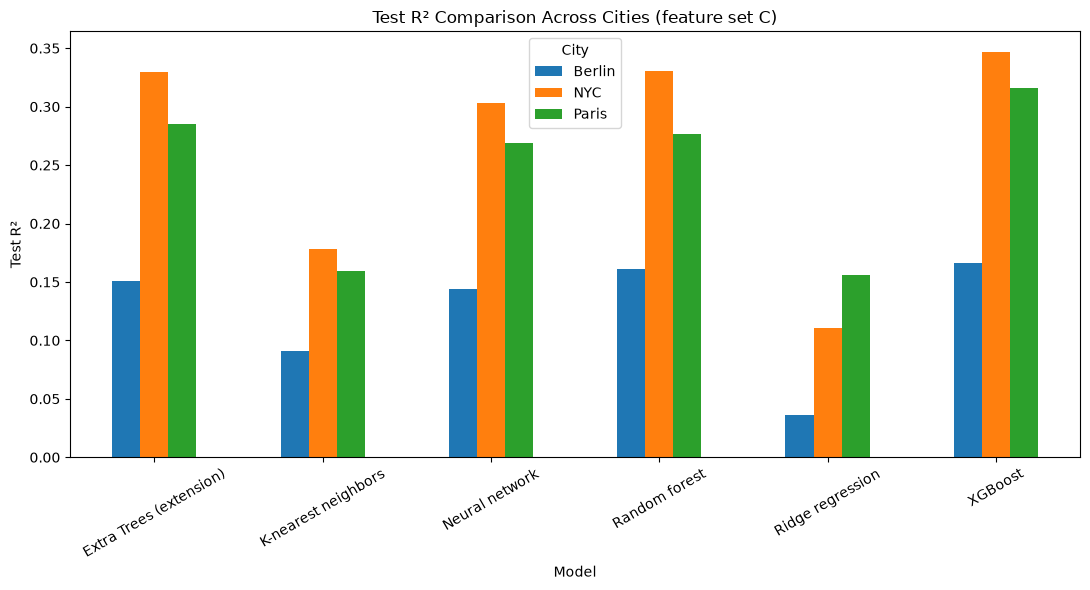

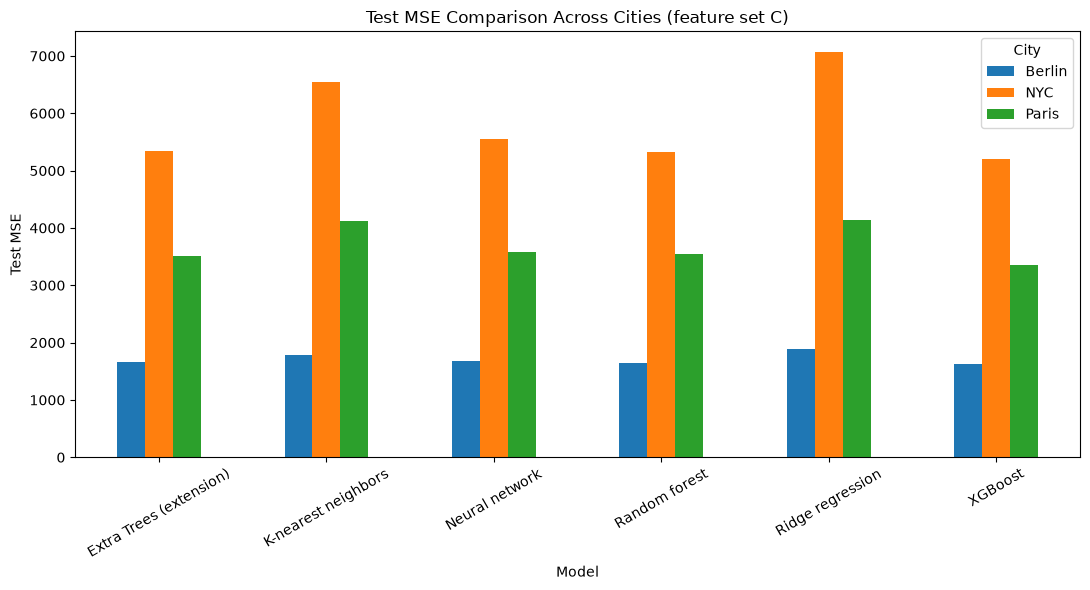

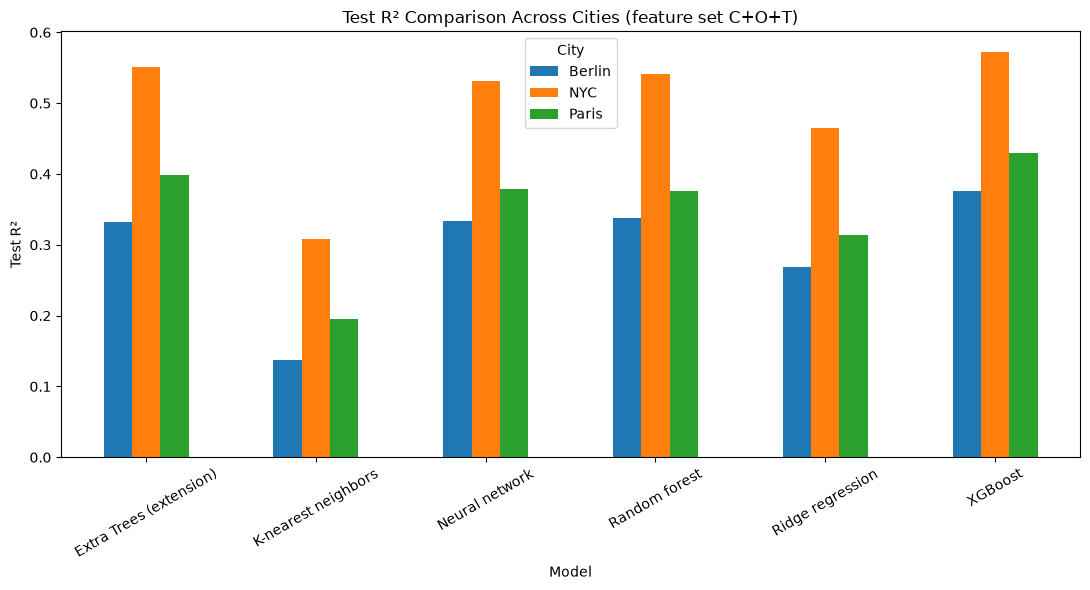

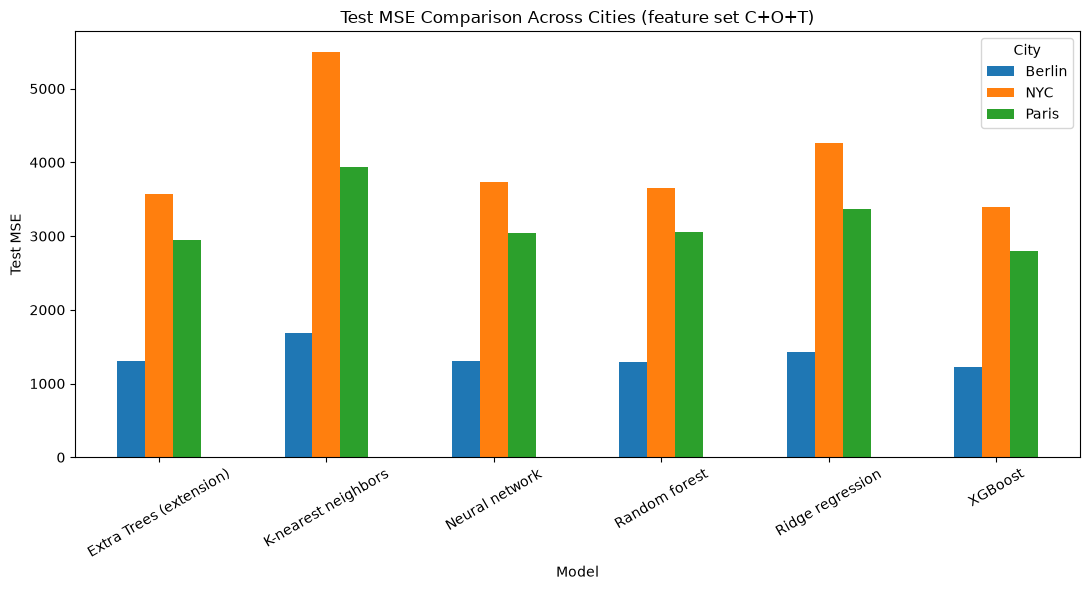

In [18]:
# Visual comparison: test R² and MSE by city, one figure per feature set.
for fs in FEATURE_SETS_TO_RUN:
    plot_df = comparison_all[comparison_all["feature_set"] == fs].pivot(
        index="model", columns="city", values="test_r2"
    )
    ax = plot_df.plot(kind="bar", figsize=(11, 6))
    ax.set_title(f"Test R² Comparison Across Cities (feature set {fs})")
    ax.set_ylabel("Test R²")
    ax.set_xlabel("Model")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="City")
    plt.tight_layout()
    plt.show()

    plot_mse = comparison_all[comparison_all["feature_set"] == fs].pivot(
        index="model", columns="city", values="test_mse"
    )
    ax = plot_mse.plot(kind="bar", figsize=(11, 6))
    ax.set_title(f"Test MSE Comparison Across Cities (feature set {fs})")
    ax.set_ylabel("Test MSE")
    ax.set_xlabel("Model")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="City")
    plt.tight_layout()
    plt.show()

## 10. Label-transformation experiment (paper Tables 2, 4, 5)

The paper reports that a log-transformed label improves XGBoost a lot, even without price thresholding (NYC test R² 0.195 -> 0.669 on continuous features, Table 2). Two cautions when comparing with it:

1. The paper's log-label R² and MSE are computed **in log space**, while its raw-label values are in dollars, so the two are not on the same scale. We report both: *model-scale* metrics (the space the model was trained on, which is what the paper tabulates) and *dollar-scale* metrics (comparable across labels).
2. We use `log1p(price)` (prices are strictly positive so this is equivalent in spirit to `log(price)`).

For every city and feature set, XGBoost is trained with the raw and the log label, both with the $500 cut-off and without it (all positive prices kept).

In [19]:
nocap_splits = {}
for city, path in DATA_PATHS.items():
    frame = load_city(path, price_cap=None)[0]
    nocap_splits[city] = make_split(frame)
    print(f"{city}: {len(frame):,} listings without the ${PRICE_CAP} cut-off "
          f"(max price {frame['price_numeric'].max():,.0f})")

log_experiment_rows = []
for fs in FEATURE_SETS_TO_RUN:
    for threshold_name, split_dict in [(f"${PRICE_CAP} cutoff", splits), (f"No ${PRICE_CAP} cutoff", nocap_splits)]:
        for city, (X_train, X_val, X_test, y_train, y_val, y_test) in split_dict.items():
            for label_mode in ["raw", "log"]:
                pipe = Pipeline([
                    ("preprocess", make_preprocessor(fs)),
                    ("model", make_xgb())
                ])
                target_train = np.log1p(y_train) if label_mode == "log" else y_train
                pipe.fit(X_train, target_train)
                pred_train = pipe.predict(X_train)
                pred_test = pipe.predict(X_test)

                if label_mode == "log":
                    pred_test_dollars = np.maximum(np.expm1(pred_test), 0)
                    train_mse_ms = mean_squared_error(np.log1p(y_train), pred_train)
                    train_r2_ms = r2_score(np.log1p(y_train), pred_train)
                    test_mse_ms = mean_squared_error(np.log1p(y_test), pred_test)
                    test_r2_ms = r2_score(np.log1p(y_test), pred_test)
                else:
                    pred_test_dollars = pred_test
                    train_mse_ms = mean_squared_error(y_train, pred_train)
                    train_r2_ms = r2_score(y_train, pred_train)
                    test_mse_ms = mean_squared_error(y_test, pred_test)
                    test_r2_ms = r2_score(y_test, pred_test)

                log_experiment_rows.append({
                    "feature_set": fs, "city": city, "threshold": threshold_name, "label": label_mode,
                    "train_mse_model_scale": train_mse_ms, "train_r2_model_scale": train_r2_ms,
                    "test_mse_model_scale": test_mse_ms, "test_r2_model_scale": test_r2_ms,
                    "test_mse_dollars": mean_squared_error(y_test, pred_test_dollars),
                    "test_r2_dollars": r2_score(y_test, pred_test_dollars),
                })
        print(f"feature set {fs} | {threshold_name}: done")

log_results_df = pd.DataFrame(log_experiment_rows)
display(log_results_df.round(4))

NYC: 48,884 listings without the $500 cut-off (max price 10,000)
Paris: 59,870 listings without the $500 cut-off (max price 25,000)
Berlin: 22,544 listings without the $500 cut-off (max price 9,000)
feature set C | $500 cutoff: done
feature set C | No $500 cutoff: done
feature set C+O+T | $500 cutoff: done
feature set C+O+T | No $500 cutoff: done


,feature_set,city,threshold,label,train_mse_model_scale,train_r2_model_scale,test_mse_model_scale,test_r2_model_scale,test_mse_dollars,test_r2_dollars
0,C,NYC,$500 cutoff,raw,4259.1245,0.4470,5196.6182,0.3471,5196.6182,0.3471
1,C,NYC,$500 cutoff,log,0.1982,0.4873,0.2332,0.4022,5545.0488,0.3033
2,C,Paris,$500 cutoff,raw,2774.2854,0.4212,3351.2343,0.3160,3351.2343,0.3160
3,C,Paris,$500 cutoff,log,0.1887,0.3999,0.2142,0.3284,3546.0459,0.2762
4,C,Berlin,$500 cutoff,raw,1051.9308,0.4698,1634.2150,0.1666,1634.2150,0.1666
5,C,Berlin,$500 cutoff,log,0.1946,0.4157,0.2690,0.2144,1646.8427,0.1601
6,C,NYC,No $500 cutoff,raw,26283.0742,0.6020,32208.4902,0.1757,32208.4902,0.1757
7,C,NYC,No $500 cutoff,log,0.2467,0.4876,0.2819,0.3790,34185.9883,0.1251
8,C,Paris,No $500 cutoff,raw,10509.1067,0.7932,15984.3127,0.2294,15984.3127,0.2294
9,C,Paris,No $500 cutoff,log,0.2162,0.4472,0.2400,0.3732,15824.9982,0.2371


In [20]:
# Reported (paper Tables 1, 2, 4, 5) vs ours for XGBoost, in the label's own scale.
# "not stated": the paper does not say whether the log rows in Tables 4-5 use the $500 cut-off,
# so both of our variants are shown next to the reported value.
reference_xgb_label = pd.DataFrame([
    {"city": "NYC",   "feature_set": "C",     "threshold": f"${PRICE_CAP} cutoff",    "label": "raw",
     "reported_train_mse": 2273.98, "reported_train_r2": 0.669, "reported_test_mse": 2357.83, "reported_test_r2": 0.665},
    {"city": "NYC",   "feature_set": "C",     "threshold": f"No ${PRICE_CAP} cutoff", "label": "raw",
     "reported_train_mse": 16748.6, "reported_train_r2": 0.558, "reported_test_mse": 58003.1, "reported_test_r2": 0.195},
    {"city": "NYC",   "feature_set": "C",     "threshold": f"No ${PRICE_CAP} cutoff", "label": "log",
     "reported_train_mse": 0.13905, "reported_train_r2": 0.695, "reported_test_mse": 0.14765, "reported_test_r2": 0.669},
    {"city": "NYC",   "feature_set": "C+O+T", "threshold": f"${PRICE_CAP} cutoff",    "label": "raw",
     "reported_train_mse": 1885.25, "reported_train_r2": 0.724, "reported_test_mse": 2078.78, "reported_test_r2": 0.706},
    {"city": "NYC",   "feature_set": "C+O+T", "threshold": "not stated",              "label": "log",
     "reported_train_mse": 0.11383, "reported_train_r2": 0.749, "reported_test_mse": 0.11731, "reported_test_r2": 0.740},
    {"city": "Paris", "feature_set": "C+O+T", "threshold": f"${PRICE_CAP} cutoff",    "label": "raw",
     "reported_train_mse": 1308.47, "reported_train_r2": 0.697, "reported_test_mse": 1413.89, "reported_test_r2": 0.691},
    {"city": "Paris", "feature_set": "C+O+T", "threshold": "not stated",              "label": "log",
     "reported_train_mse": 0.11114, "reported_train_r2": 0.722, "reported_test_mse": 0.11667, "reported_test_r2": 0.704},
])

label_comparison_rows = []
for _, ref in reference_xgb_label.iterrows():
    if ref["feature_set"] not in FEATURE_SETS_TO_RUN:
        continue
    ours = log_results_df[
        (log_results_df["city"] == ref["city"]) & (log_results_df["feature_set"] == ref["feature_set"]) &
        (log_results_df["label"] == ref["label"])
    ]
    if ref["threshold"] != "not stated":
        ours = ours[ours["threshold"] == ref["threshold"]]
    for _, o in ours.iterrows():
        label_comparison_rows.append({
            "City": ref["city"], "Feature set": ref["feature_set"], "Label": ref["label"],
            "Paper threshold": ref["threshold"], "Our threshold": o["threshold"],
            "Reported test MSE": ref["reported_test_mse"], "Our test MSE (label scale)": o["test_mse_model_scale"],
            "Reported test R²": ref["reported_test_r2"], "Our test R² (label scale)": o["test_r2_model_scale"],
            "Reported train R²": ref["reported_train_r2"], "Our train R² (label scale)": o["train_r2_model_scale"],
        })

label_comparison_df = pd.DataFrame(label_comparison_rows)
display(label_comparison_df.round(4))

,City,Feature set,Label,Paper threshold,Our threshold,Reported test MSE,Our test MSE (label scale),Reported test R²,Our test R² (label scale),Reported train R²,Our train R² (label scale)
0,NYC,C,raw,$500 cutoff,$500 cutoff,2357.8300,5196.6182,0.665,0.3471,0.669,0.4470
1,NYC,C,raw,No $500 cutoff,No $500 cutoff,58003.1000,32208.4902,0.195,0.1757,0.558,0.6020
2,NYC,C,log,No $500 cutoff,No $500 cutoff,0.1476,0.2819,0.669,0.3790,0.695,0.4876
3,NYC,C+O+T,raw,$500 cutoff,$500 cutoff,2078.7800,3400.5103,0.706,0.5727,0.724,0.7019
4,NYC,C+O+T,log,not stated,$500 cutoff,0.1173,0.1271,0.740,0.6742,0.749,0.7622
5,NYC,C+O+T,log,not stated,No $500 cutoff,0.1173,0.1767,0.740,0.6108,0.749,0.7492
6,Paris,C+O+T,raw,$500 cutoff,$500 cutoff,1413.8900,2796.3223,0.691,0.4292,0.697,0.5890
7,Paris,C+O+T,log,not stated,$500 cutoff,0.1167,0.1579,0.704,0.5049,0.722,0.6122
8,Paris,C+O+T,log,not stated,No $500 cutoff,0.1167,0.1797,0.704,0.5308,0.722,0.6382


In [21]:
# Label-transformation findings generated from THIS run (dollar-scale and label-scale R²).
print("Label-transformation findings generated from this run\n")
for fs in FEATURE_SETS_TO_RUN:
    print(f"--- Feature set {fs} ---")
    for city in splits:
        for thr in log_results_df["threshold"].unique():
            sub = log_results_df[(log_results_df["feature_set"] == fs) & (log_results_df["city"] == city) &
                                 (log_results_df["threshold"] == thr)]
            raw = sub[sub["label"] == "raw"].iloc[0]
            lg = sub[sub["label"] == "log"].iloc[0]
            better = "log" if lg["test_r2_dollars"] > raw["test_r2_dollars"] else "raw"
            print(f"{city:6s} | {thr:16s} | dollar-scale test R²: raw {raw['test_r2_dollars']:.3f} vs log {lg['test_r2_dollars']:.3f} "
                  f"-> {better} label better | log-space test R² of the log model: {lg['test_r2_model_scale']:.3f}")
    print()

Label-transformation findings generated from this run

--- Feature set C ---
NYC    | $500 cutoff      | dollar-scale test R²: raw 0.347 vs log 0.303 -> raw label better | log-space test R² of the log model: 0.402
NYC    | No $500 cutoff   | dollar-scale test R²: raw 0.176 vs log 0.125 -> raw label better | log-space test R² of the log model: 0.379
Paris  | $500 cutoff      | dollar-scale test R²: raw 0.316 vs log 0.276 -> raw label better | log-space test R² of the log model: 0.328
Paris  | No $500 cutoff   | dollar-scale test R²: raw 0.229 vs log 0.237 -> log label better | log-space test R² of the log model: 0.373
Berlin | $500 cutoff      | dollar-scale test R²: raw 0.167 vs log 0.160 -> raw label better | log-space test R² of the log model: 0.214
Berlin | No $500 cutoff   | dollar-scale test R²: raw -3.204 vs log 0.160 -> log label better | log-space test R² of the log model: 0.236

--- Feature set C+O+T ---
NYC    | $500 cutoff      | dollar-scale test R²: raw 0.573 vs log 0.552 

### Label-transformation results and discussion

- **With the $500 cut-off, the log label does not improve dollar-scale R² in any city.** Raw vs log: feature set C, NYC 0.347 vs 0.303, Paris 0.316 vs 0.276, Berlin 0.167 vs 0.160; feature set C+O+T, NYC 0.573 vs 0.552, Paris 0.429 vs 0.400, Berlin 0.377 vs 0.367.
- **Without the cut-off, the log label helps where extreme prices hurt most.** The files contain listings priced up to $10,000 (NYC), $25,000 (Paris) and $9,000 (Berlin). In Berlin the raw label collapses to R² of -3.204 (C) and -2.930 (C+O+T), while the log label gives 0.160 and 0.275. The effect is small or absent elsewhere: Paris with C is marginally better with the log label (0.237 vs 0.229), but NYC and Paris with C+O+T and NYC with C are better with the raw label (for example NYC C+O+T 0.243 vs 0.214).
- **Why the log label does not automatically help in dollars.** A model trained on `log1p(price)` minimises error in log space, and `expm1` of its prediction estimates a typical (median-like) price. That tends to under-predict the expensive listings that dominate dollar-scale squared error, especially once the cut-off has already removed the extreme prices.
- **Comparison with the paper.** The paper's log-label numbers are in log space, whereas its raw-label numbers are in dollars. In log space, our log-label XGBoost reaches R² of 0.674 on NYC with C+O+T and the cut-off (0.611 without) against the paper's 0.740, and 0.505 on Paris (0.531 without) against 0.704. The paper's headline jump on NYC with C and no cut-off (0.195 to 0.669) mixes the two scales; on our data the corresponding values are 0.176 (dollars, raw) and 0.379 (log space), while on the dollar scale the log label was worse (0.125).

## 11. Cross-city transfer-learning experiment (paper Tables 6-7)

The reference paper trains an MLP on NYC, Paris, or the combined NYC + Paris data, then evaluates transfer to Berlin using a log-price label. This notebook runs a closest-version comparison with the shared numeric features, and a second view that adds room type and listing-title text.

**Important preprocessing detail:** for the primary `per-city scaler` experiment, the numeric scaler for each city is fitted on that city's training features only. For Berlin evaluation, this uses Berlin training features without Berlin labels, which is an unsupervised target-domain preprocessing step. It is therefore not a strictly zero-access, source-only transfer setup. A pooled-scaler diagnostic is also shown to illustrate the effect of using source-city scaling on a different city's coordinates.


In [22]:
def to_dense(matrix):
    return matrix.toarray() if hasattr(matrix, "toarray") else np.asarray(matrix)

def make_transfer_mlp():
    return MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="sgd",
        learning_rate_init=0.005,
        momentum=0.9,
        nesterovs_momentum=True,
        alpha=0.005,
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.10,
        tol=1e-4,
        n_iter_no_change=10,
        random_state=RANDOM_STATE
    )

VIEWS = ["C only", "C + room_type + text"]
TRAIN_CHOICES = {"NYC only": ["NYC"], "Paris only": ["Paris"], "NYC + Paris": ["NYC", "Paris"]}
TEST_PART, TRAIN_PART_X, TRAIN_PART_Y, TEST_PART_Y = 2, 0, 3, 5   # indices into the split tuples

# One numeric preprocessor per city, fitted on that city's TRAINING features only (no labels).
city_numeric = {}
for _city, _split in splits.items():
    _pipe = make_numeric_block()
    _pipe.fit(_split[TRAIN_PART_X][common_features])
    city_numeric[_city] = _pipe

def transfer_features(train_cities, test_cities, scaling, view):
    X_train = pd.concat([splits[c][TRAIN_PART_X] for c in train_cities])
    X_tests = [splits[c][TEST_PART] for c in test_cities]

    if scaling == "per-city scaler":
        train_num = np.vstack([city_numeric[c].transform(splits[c][TRAIN_PART_X][common_features]) for c in train_cities])
        test_num = np.vstack([city_numeric[c].transform(Xt[common_features]) for c, Xt in zip(test_cities, X_tests)])
    else:  # pooled scaler fitted on the training cities only
        pooled = make_numeric_block()
        train_num = pooled.fit_transform(X_train[common_features])
        test_num = np.vstack([pooled.transform(Xt[common_features]) for Xt in X_tests])

    train_blocks, test_blocks = [train_num], [test_num]
    if view != "C only":
        X_test_all = pd.concat(X_tests)
        encoder = OneHotEncoder(handle_unknown="ignore")
        train_blocks.append(to_dense(encoder.fit_transform(X_train[[ROOM_COL]])))
        test_blocks.append(to_dense(encoder.transform(X_test_all[[ROOM_COL]])))
        text_block = make_text_block()
        train_blocks.append(to_dense(text_block.fit_transform(X_train[TEXT_COL])))
        test_blocks.append(to_dense(text_block.transform(X_test_all[TEXT_COL])))
    return np.hstack(train_blocks), np.hstack(test_blocks)

def run_transfer(experiment, train_name, train_cities, test_name, test_cities, scaling, view):
    X_tr, X_te = transfer_features(train_cities, test_cities, scaling, view)
    y_tr = np.concatenate([splits[c][TRAIN_PART_Y].values for c in train_cities])
    y_te = np.concatenate([splits[c][TEST_PART_Y].values for c in test_cities])
    y_tr_log = np.log1p(y_tr)

    mlp = make_transfer_mlp()
    mlp.fit(X_tr, y_tr_log)

    # Keep predictions inside the log-price range seen in training, so a bad extrapolation
    # cannot produce astronomically large dollar values.
    lo, hi = y_tr_log.min(), y_tr_log.max()
    pred_tr_log = np.clip(mlp.predict(X_tr), lo, hi)
    pred_te_log = np.clip(mlp.predict(X_te), lo, hi)
    pred_te_dollars = np.expm1(pred_te_log)

    return {
        "Experiment": experiment, "Feature view": view, "Scaling": scaling,
        "Training data": train_name, "Test data": test_name,
        "Train MSE (log)": mean_squared_error(y_tr_log, pred_tr_log),
        "Train R² (log)": r2_score(y_tr_log, pred_tr_log),
        "Test MSE (log)": mean_squared_error(np.log1p(y_te), pred_te_log),
        "Test R² (log)": r2_score(np.log1p(y_te), pred_te_log),
        "Test MSE ($)": mean_squared_error(y_te, pred_te_dollars),
        "Test R² ($)": r2_score(y_te, pred_te_dollars),
        "Epochs run": mlp.n_iter_,
    }

transfer_rows = []
for view in VIEWS:
    # Table 6 analogue: evaluated on the held-out test data of the training cities themselves.
    for train_name, train_cities in TRAIN_CHOICES.items():
        transfer_rows.append(run_transfer(
            "Table 6 analogue (own test sets)", train_name, train_cities,
            train_name.replace(" only", ""), train_cities, "per-city scaler", view))
    # Table 7 analogue: evaluated on the unseen Berlin test split.
    for scaling in ["per-city scaler", "pooled scaler (diagnostic)"]:
        for train_name, train_cities in TRAIN_CHOICES.items():
            transfer_rows.append(run_transfer(
                "Table 7 analogue (Berlin)", train_name, train_cities,
                "Berlin", ["Berlin"], scaling, view))
    print(f"view '{view}': done")

transfer_results_df = pd.DataFrame(transfer_rows)
display(transfer_results_df.round(4))

view 'C only': done
view 'C + room_type + text': done


,Experiment,Feature view,Scaling,Training data,Test data,Train MSE (log),Train R² (log),Test MSE (log),Test R² (log),Test MSE ($),Test R² ($),Epochs run
0,Table 6 analogue (own test sets),C only,per-city scaler,NYC only,NYC,0.2574,0.3342,0.2628,0.3266,5982.3809,0.2484,77
1,Table 6 analogue (own test sets),C only,per-city scaler,Paris only,Paris,0.2230,0.2907,0.2236,0.2988,3676.5348,0.2496,83
2,Table 6 analogue (own test sets),C only,per-city scaler,NYC + Paris,NYC + Paris,0.2499,0.3154,0.2543,0.3121,4966.2802,0.2427,145
3,Table 7 analogue (Berlin),C only,per-city scaler,NYC only,Berlin,0.2574,0.3342,1.1049,-2.2263,7273.5868,-2.7094,77
4,Table 7 analogue (Berlin),C only,per-city scaler,Paris only,Berlin,0.2230,0.2907,0.6654,-0.9431,3155.5034,-0.6093,83
5,Table 7 analogue (Berlin),C only,per-city scaler,NYC + Paris,Berlin,0.2499,0.3154,0.7387,-1.1570,3586.8117,-0.8292,145
6,Table 7 analogue (Berlin),C only,pooled scaler (diagnostic),NYC only,Berlin,0.2574,0.3342,5.8052,-15.9518,197798.0062,-99.8743,77
7,Table 7 analogue (Berlin),C only,pooled scaler (diagnostic),Paris only,Berlin,0.2230,0.2907,5.8052,-15.9518,197798.0062,-99.8743,83
8,Table 7 analogue (Berlin),C only,pooled scaler (diagnostic),NYC + Paris,Berlin,0.2983,0.1828,0.4091,-0.1947,1997.5569,-0.0187,126
9,Table 6 analogue (own test sets),C + room_type + text,per-city scaler,NYC only,NYC,0.1338,0.6539,0.1476,0.6217,3943.6703,0.5045,106


In [23]:
# Reported (paper Tables 6 and 7, log-price label, log-space metrics) vs ours (per-city scaler).
reference_transfer = pd.DataFrame([
    {"Experiment": "Table 6 analogue (own test sets)", "Training data": "NYC only",
     "reported_train_mse": 0.10525, "reported_train_r2": 0.769, "reported_test_mse": 0.11723, "reported_test_r2": 0.741},
    {"Experiment": "Table 6 analogue (own test sets)", "Training data": "Paris only",
     "reported_train_mse": 0.09448, "reported_train_r2": 0.762, "reported_test_mse": 0.11277, "reported_test_r2": 0.716},
    {"Experiment": "Table 6 analogue (own test sets)", "Training data": "NYC + Paris",
     "reported_train_mse": 0.08331, "reported_train_r2": 0.816, "reported_test_mse": 0.10357, "reported_test_r2": 0.773},
    {"Experiment": "Table 7 analogue (Berlin)", "Training data": "NYC only",
     "reported_train_mse": 0.10653, "reported_train_r2": 0.765, "reported_test_mse": 1.78007, "reported_test_r2": -3.512},
    {"Experiment": "Table 7 analogue (Berlin)", "Training data": "Paris only",
     "reported_train_mse": 0.09494, "reported_train_r2": 0.761, "reported_test_mse": 7.26637, "reported_test_r2": -17.42},
    {"Experiment": "Table 7 analogue (Berlin)", "Training data": "NYC + Paris",
     "reported_train_mse": 0.10461, "reported_train_r2": 0.763, "reported_test_mse": 0.19163, "reported_test_r2": 0.514},
])

main_transfer = transfer_results_df[transfer_results_df["Scaling"] == "per-city scaler"]
transfer_comparison_df = main_transfer.merge(reference_transfer, on=["Experiment", "Training data"], how="left")
transfer_comparison_df = transfer_comparison_df[[
    "Experiment", "Feature view", "Training data",
    "reported_train_r2", "Train R² (log)", "reported_test_mse", "Test MSE (log)",
    "reported_test_r2", "Test R² (log)",
]].rename(columns={
    "reported_train_r2": "Reported train R²", "Train R² (log)": "Our train R²",
    "reported_test_mse": "Reported test MSE", "Test MSE (log)": "Our test MSE",
    "reported_test_r2": "Reported test R²", "Test R² (log)": "Our test R²",
})
display(transfer_comparison_df.round(4))

# Read-out generated from this run: does combined training beat the best single city on Berlin?
print("\nTable 7 analogue read-out generated from this run (per-city scaler, log-space R² on Berlin):")
for view in VIEWS:
    t7 = main_transfer[(main_transfer["Experiment"] == "Table 7 analogue (Berlin)") &
                       (main_transfer["Feature view"] == view)].set_index("Training data")
    comb = t7.loc["NYC + Paris", "Test R² (log)"]
    best_single = max(t7.loc["NYC only", "Test R² (log)"], t7.loc["Paris only", "Test R² (log)"])
    verdict = "BETTER than" if comb > best_single else "NOT better than"
    print(f"  {view}: NYC+Paris = {comb:.3f}; best single city = {best_single:.3f} "
          f"-> combined training is {verdict} the best single-city model "
          f"(paper: combined 0.514 vs NYC-only -3.512 and Paris-only -17.42).")

print("\nPooled-scaler diagnostic on Berlin (log-space R²):")
diag = transfer_results_df[(transfer_results_df["Scaling"] == "pooled scaler (diagnostic)")]
display(diag[["Feature view", "Training data", "Test R² (log)", "Test R² ($)"]].round(4))

,Experiment,Feature view,Training data,Reported train R²,Our train R²,Reported test MSE,Our test MSE,Reported test R²,Our test R²
0,Table 6 analogue (own test sets),C only,NYC only,0.769,0.3342,0.1172,0.2628,0.741,0.3266
1,Table 6 analogue (own test sets),C only,Paris only,0.762,0.2907,0.1128,0.2236,0.716,0.2988
2,Table 6 analogue (own test sets),C only,NYC + Paris,0.816,0.3154,0.1036,0.2543,0.773,0.3121
3,Table 7 analogue (Berlin),C only,NYC only,0.765,0.3342,1.7801,1.1049,-3.512,-2.2263
4,Table 7 analogue (Berlin),C only,Paris only,0.761,0.2907,7.2664,0.6654,-17.420,-0.9431
5,Table 7 analogue (Berlin),C only,NYC + Paris,0.763,0.3154,0.1916,0.7387,0.514,-1.1570
6,Table 6 analogue (own test sets),C + room_type + text,NYC only,0.769,0.6539,0.1172,0.1476,0.741,0.6217
7,Table 6 analogue (own test sets),C + room_type + text,Paris only,0.762,0.4780,0.1128,0.1798,0.716,0.4362
8,Table 6 analogue (own test sets),C + room_type + text,NYC + Paris,0.816,0.5697,0.1036,0.1695,0.773,0.5416
9,Table 7 analogue (Berlin),C + room_type + text,NYC only,0.765,0.6539,1.7801,0.8025,-3.512,-1.3435



Table 7 analogue read-out generated from this run (per-city scaler, log-space R² on Berlin):
  C only: NYC+Paris = -1.157; best single city = -0.943 -> combined training is NOT better than the best single-city model (paper: combined 0.514 vs NYC-only -3.512 and Paris-only -17.42).
  C + room_type + text: NYC+Paris = -0.565; best single city = -0.184 -> combined training is NOT better than the best single-city model (paper: combined 0.514 vs NYC-only -3.512 and Paris-only -17.42).

Pooled-scaler diagnostic on Berlin (log-space R²):


,Feature view,Training data,Test R² (log),Test R² ($)
6,C only,NYC only,-15.9518,-99.8743
7,C only,Paris only,-15.9518,-99.8743
8,C only,NYC + Paris,-0.1947,-0.0187
15,C + room_type + text,NYC only,-15.9518,-99.8743
16,C + room_type + text,Paris only,-12.9684,-63.9121
17,C + room_type + text,NYC + Paris,-0.3331,-0.0846


### Cross-city transfer results and discussion

**Berlin (Table 7 analogue).** Log-space test R² on Berlin with the per-city scaler:

| Feature view | NYC only | Paris only | NYC + Paris |
|---|---:|---:|---:|
| C only | -2.226 | -0.943 | -1.157 |
| C + room_type + text | -1.343 | -0.184 | -0.565 |
| Paper (C+O) | -3.512 | -17.42 | 0.514 |

- **The paper's claim is not reproduced.** Combined NYC+Paris training is not better than the best single-city model in either view, and every R² is negative, meaning none of the models beats predicting Berlin's mean log price.
- **Room type and title text help transfer.** The view with room type and text improves on C only for all three training sets, so these features carry some price information that is not city-specific.
- **A likely contributor is the price level.** Berlin's median price is 45, against 101 for NYC and 79 for Paris (dataset summary), so models that learned another city's price level will over-predict in Berlin. This was not tested separately.
- **Other limits.** Latitude and longitude are city-specific, so what a model learns about location in NYC or Paris does not carry over to Berlin. Berlin titles also contain German words that are unseen in NYC and Paris titles. The shared feature set is much smaller than the paper's, so the mismatch does not by itself disprove the paper's finding.

**Within-city (Table 6 analogue).** With room type and text, the MLP reaches test R² (log space) of 0.622 on NYC, 0.436 on Paris and 0.542 on the pooled NYC+Paris test set, against the paper's 0.741, 0.716 and 0.773. With C only the values are 0.327, 0.299 and 0.312. The pooled score falls between the two single-city scores, so the paper's gain from combining the cities is not seen; the pooled test set mixes the two cities, so this comparison is not exact.

**Scaling.** Latitude and longitude are near-constant within a city (roughly 40.7 / -74.0 in NYC, 48.9 / 2.3 in Paris, 52.5 / 13.4 in Berlin). A single scaler fitted on the training cities puts Berlin's coordinates hundreds of standard deviations from the training mean, and the network extrapolates wildly. The main results therefore standardise each city with its own training-split feature statistics, so coordinates become offsets from the local city centre. For Berlin this uses Berlin's training features but no Berlin labels; it is an unsupervised target-domain step, not a strictly source-only transfer setup.

**Pooled-scaler diagnostic.** With one scaler fitted on the source cities, NYC-only and Paris-only models on C give an identical R² of -15.952 (log space), consistent with every prediction being clipped to the same upper bound (both training sets have the same maximum price). The pooled-scaler NYC+Paris models score -0.195 (C) and -0.333 (C + room_type + text), still negative. These rows are diagnostic only.

## 12. Summary of results (generated from this run)

The cell below assembles a summary from the computed result tables. Paper-reported values are reference constants and are not results computed by this notebook.

In [24]:
summary_lines = []
add = summary_lines.append

add("PART 1 - REPRODUCTION")
add(f"Data: {', '.join(f'{c} ({len(raw_data[c]):,} listings after the ${PRICE_CAP} filter)' for c in raw_data)}.")
add(f"Feature set C = {len(common_features)} numeric columns common to all three files; C+O+T adds "
    f"{', '.join(CAT_COLS)} and the listing title (TF-IDF -> SVD {TEXT_SVD_DIM}).")
for fs in FEATURE_SETS_TO_RUN:
    for city in splits:
        sub = results_df[(results_df["feature_set"] == fs) & (results_df["city"] == city)]
        best = sub.loc[sub["test_r2"].idxmax()]
        worst = sub.loc[sub["test_r2"].idxmin()]
        add(f"  [{fs}] {city}: best reference model {best['model']} (test R² {best['test_r2']:.3f}); "
            f"weakest {worst['model']} ({worst['test_r2']:.3f}).")
for fs in FEATURE_SETS_TO_RUN:
    xg = get_metric(results_df, "NYC", "XGBoost", fs, "test_r2")
    add(f"  NYC XGBoost test R² on feature set {fs}: {xg:.3f} (paper: 0.665 on continuous features, "
        f"0.706 with categorical + text).")

add("")
add("PART 2 - EXTENSION (Extra Trees)")
for fs in FEATURE_SETS_TO_RUN:
    for city in splits:
        sub = verdict_df[(verdict_df["Feature set"] == fs) & (verdict_df["City"] == city)]
        better = sub[sub["Verdict"] == "Better"]["Reference model"].tolist()
        similar = sub[sub["Verdict"].str.startswith("Similar")]["Reference model"].tolist()
        worse = sub[sub["Verdict"] == "Worse"]["Reference model"].tolist()
        mixed = sub[sub["Verdict"].str.startswith("Mixed")]["Reference model"].tolist()
        add(f"  [{fs}] {city}: better than {better or 'none'}; similar to {similar or 'none'}; "
            f"worse than {worse or 'none'}" + (f"; mixed vs {mixed}" if mixed else "") + ".")

add("")
add("LABEL TRANSFORMATION (XGBoost)")
for fs in FEATURE_SETS_TO_RUN:
    for city in splits:
        for thr in log_results_df["threshold"].unique():
            sub = log_results_df[(log_results_df["feature_set"] == fs) & (log_results_df["city"] == city) &
                                 (log_results_df["threshold"] == thr)]
            raw = sub[sub["label"] == "raw"].iloc[0]
            lg = sub[sub["label"] == "log"].iloc[0]
            add(f"  [{fs}] {city}, {thr}: dollar-scale R² raw {raw['test_r2_dollars']:.3f} vs log {lg['test_r2_dollars']:.3f}; "
                f"log-space R² of the log model {lg['test_r2_model_scale']:.3f}.")

add("")
add("CROSS-CITY TRANSFER (MLP, log label, per-city scaler; log-space test R² on Berlin)")
for view in VIEWS:
    t7 = main_transfer[(main_transfer["Experiment"] == "Table 7 analogue (Berlin)") &
                       (main_transfer["Feature view"] == view)].set_index("Training data")
    add(f"  [{view}] NYC only {t7.loc['NYC only', 'Test R² (log)']:.3f}; Paris only {t7.loc['Paris only', 'Test R² (log)']:.3f}; "
        f"NYC+Paris {t7.loc['NYC + Paris', 'Test R² (log)']:.3f} (paper: -3.512 / -17.42 / 0.514).")

report_summary = "\n".join(summary_lines)
print(report_summary)

PART 1 - REPRODUCTION
Data: NYC (47,840 listings after the $500 filter), Paris (59,021 listings after the $500 filter), Berlin (22,470 listings after the $500 filter).
Feature set C = 7 numeric columns common to all three files; C+O+T adds room_type, area and the listing title (TF-IDF -> SVD 50).
  [C] NYC: best reference model XGBoost (test R² 0.347); weakest Ridge regression (0.111).
  [C] Paris: best reference model XGBoost (test R² 0.316); weakest Ridge regression (0.156).
  [C] Berlin: best reference model XGBoost (test R² 0.167); weakest Ridge regression (0.036).
  [C+O+T] NYC: best reference model XGBoost (test R² 0.573); weakest K-nearest neighbors (0.309).
  [C+O+T] Paris: best reference model XGBoost (test R² 0.429); weakest K-nearest neighbors (0.196).
  [C+O+T] Berlin: best reference model XGBoost (test R² 0.377); weakest K-nearest neighbors (0.138).
  NYC XGBoost test R² on feature set C: 0.347 (paper: 0.665 on continuous features, 0.706 with categorical + text).
  NYC XGB

In [25]:
# Save computed result tables for the written report
OUTPUT_DIR = Path("airbnb_reproduction_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

tables_to_save = {
    "dataset_summary.csv": dataset_summary,
    "all_reference_model_results.csv": results_df,
    "extra_trees_extension_results.csv": extension_df,
    "all_models_comparison.csv": comparison_all,
    "extra_trees_verdicts.csv": verdict_df,
    "reported_vs_our_nyc_table1.csv": comparison,
    "reported_vs_our_xgboost_full_features.csv": xgb_full_comparison,
    "xgboost_log_label_results.csv": log_results_df,
    "reported_vs_our_xgboost_label.csv": label_comparison_df,
    "cross_city_transfer_results.csv": transfer_results_df,
    "reported_vs_our_transfer.csv": transfer_comparison_df,
}
for filename, table in tables_to_save.items():
    if table is not None:
        table.to_csv(OUTPUT_DIR / filename, index=False)

(OUTPUT_DIR / "report_summary.txt").write_text(report_summary, encoding="utf-8")
print(f"Saved computed result tables to: {OUTPUT_DIR.resolve()}")

Saved computed result tables to: C:\Users\vaibh\OneDrive\Desktop\ML miniproject\airbnb_reproduction_outputs
